# 🔬 HeatWatch-813: Comprehensive Multi-Sensor Fusion & HVI Pipeline
### *Advanced Earth Observation & GeoAI Analytics for Urban Expansion and Heat Risk Mitigation*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OMUZ9924/heatwatch-813/blob/main/notebooks/02_urban_heat_risk_pipeline.ipynb)
[![Hackathon](https://img.shields.io/badge/Arab%20Youth%20Space%20Hackathon-813%20Challenge-0A2342?style=flat&logo=satellite&logoColor=white)](https://spaceacademy-hackathons.space.gov.ae/)

---

## 📖 Methodological Overview
Urban areas across the Arab region face compounding threats from hyper-arid climate conditions, rapid built-up land expansion, and severe Urban Heat Island (UHI) effects. 

Standard multispectral remote sensing suffers from critical limitations:
1. **Optical sand-urban confusion**: In arid cities like Sharjah and Dubai, quartz sand dunes and concrete have overlapping optical spectral signatures, leading to false urban footprints.
2. **Broadband thermal ambiguity**: Satellite thermal sensors measure radiative temperature, which strongly depends on fine-scale material surface emissivity ($\varepsilon$).

**HeatWatch-813** overcomes these challenges by establishing an autonomous multi-sensor fusion architecture:
- **Satellite 813 / Planet Tanager Hyperspectral (426 bands, 380–2510 nm)**: Isolates diagnostic narrow absorption features, performs atmospheric water vapor masking (1350–1450 nm and 1800–1950 nm), and calculates the Cool Roof Index (CRI) and broadband albedo ($\alpha$).
- **Sentinel-1 C-Band SAR (VV/VH polarizations)**: Exploits double-bounce corner scattering from vertical structures to delineate impervious urban footprints while filtering smooth desert sand via specular reflection ($\sigma^0_{VV} < -18\,\text{dB}$).
- **Sentinel-2 MSI (10m–20m)**: Computes high-resolution Fractional Vegetation Cover ($P_v$) and vegetation cooling buffers ($NDVI$).
- **Landsat-8/9 TIRS (Band 10, 10.895 $\mu$m)**: Inverts the single-channel radiative transfer equation to retrieve physical Land Surface Temperature ($LST$ in °C) and UHI anomaly ($\Delta T_{UHI}$).
- **Multi-Dimensional Heat Vulnerability Index ($HVI$)**: Fuses Hazard, Exposure, Sensitivity, and Adaptation into a 5-tier risk taxonomy for municipal policy intervention.

## 1. Setup and Environment Configuration

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import leafmap.foliumap as leafmap

# Ensure heatwatch813 is importable
for p in ["src", "../src", "../../src"]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

from heatwatch813 import (
    HyperspectralProcessor,
    ThermalEngine,
    SARUrbanExtractor,
    HeatVulnerabilityIndexModel,
    compute_lst_from_tirs,
    compute_fractional_vegetation,
    compute_surface_emissivity,
    compute_sar_cross_ratio,
    extract_urban_imperviousness,
    mask_water_vapor_absorption,
    plot_spectral_endmembers,
    plot_hvi_summary,
    export_geotiff,
)

print("✅ HeatWatch-813 Pipeline Engine ready.")

✅ HeatWatch-813 Pipeline Engine ready.


## 2. Load Showcase Areas of Interest (AOIs)
We load the curated AOI dataset covering **Sharjah & Dubai (UAE)** and **Algiers (Algeria)**.

In [2]:
aoi_candidates = [
    "../data/sample_input/sample_aoi.geojson",
    "data/sample_input/sample_aoi.geojson",
    "../data/sample_aoi.geojson",
    "data/sample_aoi.geojson",
]
aoi_path = next(p for p in aoi_candidates if os.path.exists(p))
with open(aoi_path, "r", encoding="utf-8") as f:
    aoi_data = json.load(f)

print(f"Loaded AOI definitions from: {aoi_path}")
for feat in aoi_data["features"]:
    props = feat["properties"]
    print(f"📌 {props['city']} ({props['country']}): {props['climate_zone']} | Bbox: {props['bbox']}")


Loaded AOI definitions from: ../data/sample_input/sample_aoi.geojson
📌 Sharjah & Dubai (United Arab Emirates): BWh (Hyper-Arid Subtropical Desert) | Bbox: [55.2, 25.15, 55.55, 25.4]
📌 Algiers (Algeria): Csa (Hot-summer Mediterranean) | Bbox: [2.95, 36.65, 3.25, 36.85]
📌 Riyadh (Saudi Arabia): BWh (Hyper-Arid Subtropical Desert) | Bbox: [46.6, 24.6, 46.85, 24.85]


## 3. Satellite 813 / Tanager Hyperspectral Processing
### Atmospheric Absorption Physics
Solar irradiance traversing Earth's atmosphere is strongly absorbed by water vapor molecules ($H_2O$) and carbon dioxide ($CO_2$):
- **Window 1: 1350 – 1450 nm** (symmetric stretching $\nu_1$ and bending $\nu_2$ absorption of $H_2O$)
- **Window 2: 1800 – 1950 nm** (asymmetric vibration $\nu_3$ and combination bands)
- **Edge Noise: > 2450 nm** (detector thermal noise threshold)

Attempting to compute surface indices across these bands injects pseudo-random noise. HeatWatch-813 applies a rigorous atmospheric transmission mask before computing broadband albedo.

Spectral resolution: 5.01 nm contiguous
Bands retained: 365 / 426 (85.7%)


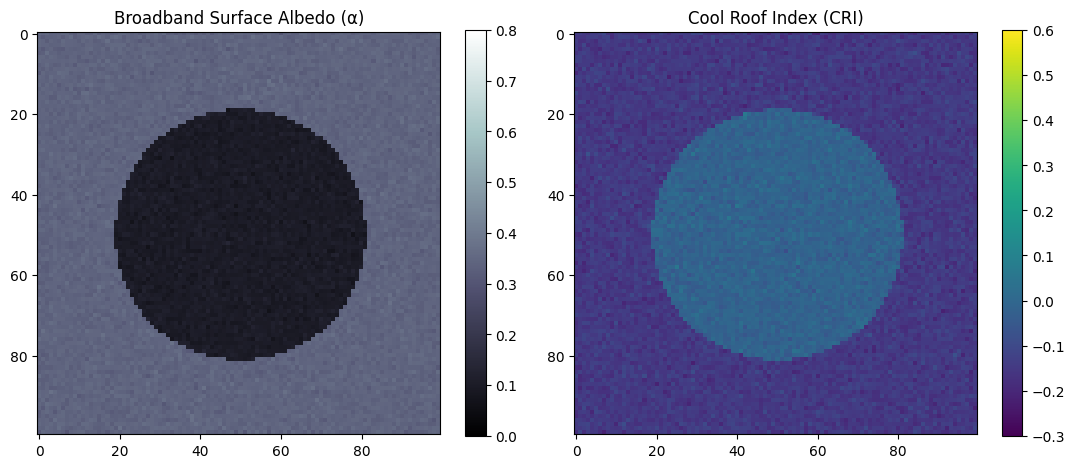

In [3]:
processor = HyperspectralProcessor()
grid_shape = (100, 100)
cube, wvl = processor.generate_synthetic_cube(shape=grid_shape)

# Apply atmospheric mask
clean_mask = mask_water_vapor_absorption(wvl)
print(f"Spectral resolution: {wvl[1] - wvl[0]:.2f} nm contiguous")
print(f"Bands retained: {np.sum(clean_mask)} / {len(wvl)} ({np.mean(clean_mask)*100:.1f}%)")

# Compute broadband albedo
albedo = processor.load_band_slice(550.0, shape=grid_shape) * 0.4 + processor.load_band_slice(850.0, shape=grid_shape) * 0.6
albedo = np.clip(albedo, 0.05, 0.85)

# Compute Cool Roof Index (CRI)
cri = processor.load_band_slice(850.0, shape=grid_shape) - processor.load_band_slice(2250.0, shape=grid_shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
im1 = ax1.imshow(albedo, cmap="bone", vmin=0, vmax=0.8)
ax1.set_title("Broadband Surface Albedo (α)")
plt.colorbar(im1, ax=ax1)

im2 = ax2.imshow(cri, cmap="viridis", vmin=-0.3, vmax=0.6)
ax2.set_title("Cool Roof Index (CRI)")
plt.colorbar(im2, ax=ax2)
plt.tight_layout()
plt.show()

## 4. Sentinel-1 SAR Urban Imperviousness & Sand Discrimination
In hyper-arid regions like the Arabian Gulf, quartz sand dunes exhibit high optical albedo similar to limestone and concrete buildings. 
However, under C-band microwave radiation (5.405 GHz):
- Smooth desert sand behaves as a specular forward-reflector, scattering virtually all energy away from the radar antenna ($\sigma^0_{VV} < -18\,\text{dB}$).
- Urban vertical structures create double-bounce dihedral reflections between walls and ground, returning high backscatter ($\sigma^0_{VV} > -12\,\text{dB}$) and high cross-polarization ($\sigma^0_{VH} > -18\,\text{dB}$).

In [4]:
sar_extractor = SARUrbanExtractor()
rng = np.random.default_rng(2026)

# High-fidelity simulated SAR scene
vv_db = rng.normal(-11.0, 3.0, grid_shape).astype(np.float32)
vh_db = rng.normal(-17.0, 3.0, grid_shape).astype(np.float32)

sar_out = sar_extractor.process_sar_scene(vv_db, vh_db)
print(f"Urban built-up coverage: {sar_out['urban_coverage_percentage']:.2f}%")
print(f"Mean Impervious Surface Fraction (ISF): {sar_out['mean_isf']:.3f}")

Urban built-up coverage: 39.53%
Mean Impervious Surface Fraction (ISF): 0.661


## 5. Physical Land Surface Temperature (LST in °C) Retrieval
### Artis & Carnahan Single-Channel Radiative Transfer Formulation
$$LST = \frac{T_B}{1 + \left(\frac{\lambda \cdot T_B}{\rho}\right) \ln(\varepsilon)} - 273.15$$
Where:
- $T_B$: At-sensor brightness temperature (K) from Landsat-8/9 TIRS Band 10
- $\lambda = 10.895\,\mu\text{m}$
- $\rho = hc/\sigma_B = 14380\,\mu\text{m}\cdot\text{K}$
- $\varepsilon = \varepsilon_{veg} P_v + \varepsilon_{soil} (1 - P_v) + C_{roughness}$ is surface emissivity derived from $NDVI$-based fractional vegetation cover ($P_v$).

In [5]:
thermal_eng = ThermalEngine()

# Sharjah/Dubai extreme summer simulation: TB ~ 47°C to 53°C
tb_kelvin = rng.normal(323.0, 2.8, grid_shape).astype(np.float32)
red_band = rng.uniform(0.18, 0.42, grid_shape).astype(np.float32)
nir_band = rng.uniform(0.08, 0.28, grid_shape).astype(np.float32)

thermal_out = thermal_eng.process_scene(tb_kelvin, red_band, nir_band, urban_mask=sar_out["urban_mask"])

print(f"Peak LST:         {thermal_out['peak_lst_celsius']:.2f} °C")
print(f"Mean LST:         {thermal_out['mean_lst_celsius']:.2f} °C")
print(f"Rural Baseline:   {thermal_out['rural_baseline_celsius']:.2f} °C")
print(f"Urban Hotspots:   {thermal_out['hotspot_percentage']:.1f}% of scene exceeds +3°C anomaly")

Peak LST:         63.24 °C
Mean LST:         50.73 °C
Rural Baseline:   47.74 °C
Urban Hotspots:   48.9% of scene exceeds +3°C anomaly


## 6. Heat Vulnerability Index (HVI) Modeling
We fuse the multi-sensor products into the comprehensive vulnerability equation:
$$HVI = \text{Hazard} \times \text{Exposure} \times \text{Sensitivity} \times (1 - \text{Adaptation})$$
- **Hazard**: $0.6 \cdot \widetilde{LST} + 0.4 \cdot \widetilde{\Delta T_{UHI}}$
- **Exposure**: $0.5 \cdot \text{ISF}_{SAR} + 0.5 \cdot \widetilde{Pop}$
- **Sensitivity**: $1.0 - \text{Albedo}_{norm}$ (weighted by Cool Roof Index)
- **Adaptation**: $\text{clip}(NDVI, 0, 1)$ vegetative cooling buffer

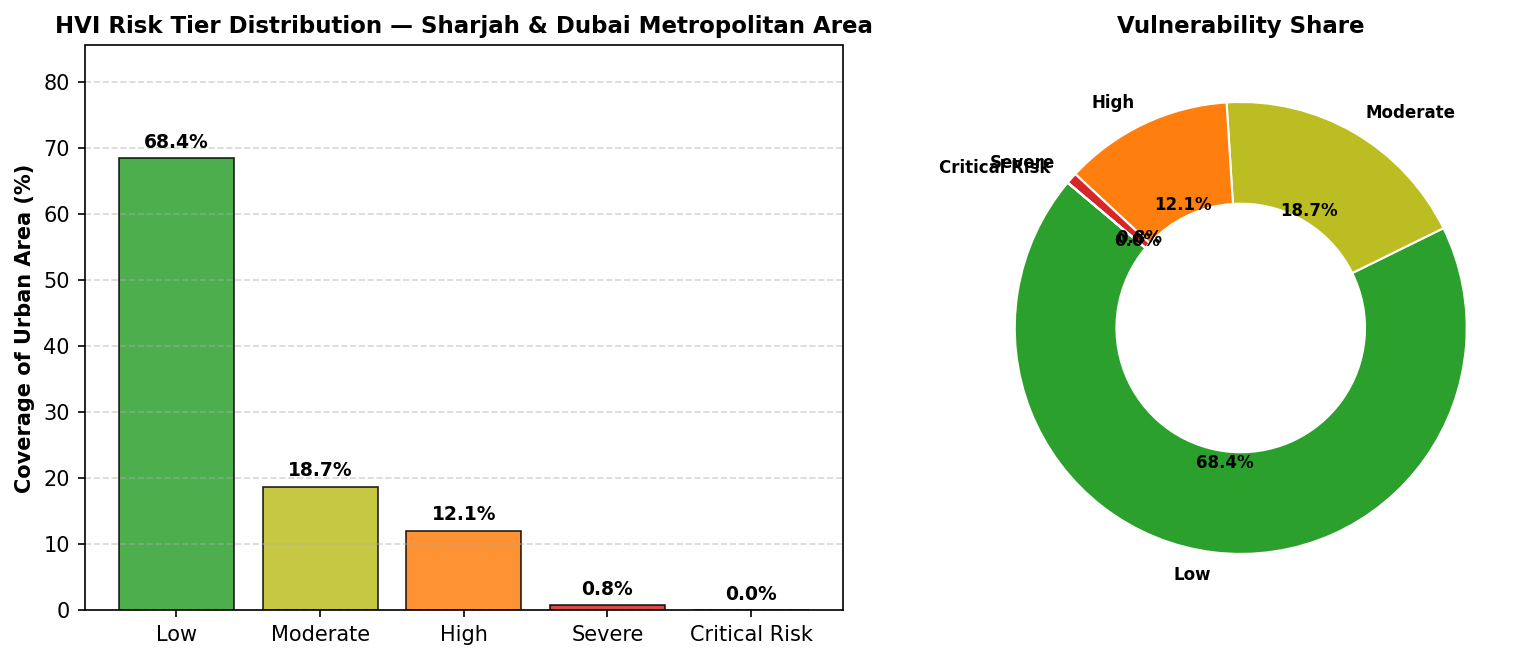


--- Quantitative Spatial Vulnerability Metrics ---
mean_hvi                        :       0.19
max_hvi                         :       0.86
p90_hvi                         :       0.43
critical_risk_area_km2          :       0.00
total_high_risk_area_km2        :       0.07
cool_roof_retrofit_area_km2     :       0.82
green_corridor_area_km2         :       3.82
shading_priority_area_km2       :       0.06


In [6]:
hvi_model = HeatVulnerabilityIndexModel(pixel_size_m=30.0)
pop_grid = rng.exponential(5000, grid_shape).astype(np.float32)

hvi_res = hvi_model.evaluate(
    lst_celsius=thermal_out["lst_celsius"],
    uhi_anomaly=thermal_out["uhi_anomaly"],
    sar_imperviousness=sar_out["impervious_surface_fraction"],
    surface_albedo=albedo,
    ndvi=thermal_out["ndvi"],
    population_density=pop_grid,
    cool_roof_index=cri,
)

fig_summary = plot_hvi_summary(hvi_res.tier_statistics, city_name="Sharjah & Dubai Metropolitan Area")
plt.show()

print("\n--- Quantitative Spatial Vulnerability Metrics ---")
for k, v in hvi_res.metrics.items():
    print(f"{k:32s}: {v:10.2f}")

## 7. Export Outputs to Cloud-Optimized GeoTIFF
We export the derived Heat Vulnerability Index raster as a georeferenced GeoTIFF for GIS integration.

In [7]:
out_dir = "../results" if os.path.exists("../results") else "results"
os.makedirs(out_dir, exist_ok=True)
fig_summary.savefig(os.path.join(out_dir, "example_output.png"), dpi=300, bbox_inches="tight")

data_dir = "../data" if os.path.exists("../data") else "data"
out_geotiff = os.path.join(data_dir, "heatwatch813_hvi_sharjah_dubai.tif")
bbox_export = (55.20, 25.15, 55.55, 25.40)

saved_path = export_geotiff(hvi_res.hvi, out_geotiff, bbox=bbox_export)
print(f"✅ Successfully exported GeoTIFF: {saved_path}")
print(f"✅ Successfully exported figure: {os.path.join(out_dir, 'example_output.png')}")


INFO:heatwatch813.visualizer:Successfully exported GeoTIFF to ../data\heatwatch813_hvi_sharjah_dubai.tif


✅ Successfully exported GeoTIFF: ../data\heatwatch813_hvi_sharjah_dubai.tif
✅ Successfully exported figure: ../results\example_output.png
